<a href="https://colab.research.google.com/github/fpv5026/FinalProjectDataAnalysis/blob/main/Occupation_DTI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DTI OpenAI GPT 20b

In [112]:
import os
print("Current working directory:", os.getcwd())


Current working directory: /content


In [113]:
import pandas as pd

typo_df = pd.read_csv('/content/erscountytypology2025edition.csv')
diff_df = pd.read_csv('/content/dti_merged_data_openai_gpt-oss-20b.csv')

print('read')


read


In [114]:
filt_df = typo_df[typo_df["Attribute"] == "Industry_Dependence_2025"]
filt_df.head()


,FIPStxt,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
6,1001,AL,Autauga County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
19,1003,AL,Baldwin County,1,Industry_Dependence_2025,5,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
32,1005,AL,Barbour County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
45,1007,AL,Bibb County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
58,1009,AL,Blount County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


In [115]:
print(filt_df.columns)
print(diff_df.columns)


Index(['FIPStxt', 'State', 'County_Name', 'Metro2023', 'Attribute', 'Value',
       'PublicationDate', 'Source'],
      dtype='object')
Index(['county_fips', 'county', 'estimate', 'low', 'high', 'mean_col',
       'Difference'],
      dtype='object')


In [116]:
diff_df.head()

,county_fips,county,estimate,low,high,mean_col,Difference
0,1005,"Barbour County, AL",1.20,1.01,1.19,1.100,0.100
1,1013,"Butler County, AL",1.20,1.01,1.19,1.100,0.100
2,1015,"Calhoun County, AL",0.65,1.37,1.58,1.475,-0.825
3,1011,"Bullock County, AL",1.45,0.78,1.01,0.895,0.555
4,1007,"Bibb County, AL",0.90,1.82,2.15,1.985,-1.085


In [117]:
filt_df = filt_df.rename(columns={"FIPStxt": "county_fips"})

merged = diff_df.merge(filt_df, on="county_fips", how="left")

merged = merged.dropna(subset=["county"])

merged.head()

,county_fips,county,estimate,low,high,mean_col,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1005,"Barbour County, AL",1.20,1.01,1.19,1.100,0.100,AL,Barbour County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1013,"Butler County, AL",1.20,1.01,1.19,1.100,0.100,AL,Butler County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1015,"Calhoun County, AL",0.65,1.37,1.58,1.475,-0.825,AL,Calhoun County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1011,"Bullock County, AL",1.45,0.78,1.01,0.895,0.555,AL,Bullock County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1007,"Bibb County, AL",0.90,1.82,2.15,1.985,-1.085,AL,Bibb County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_723/2139301631.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged, palette="coolwarm")


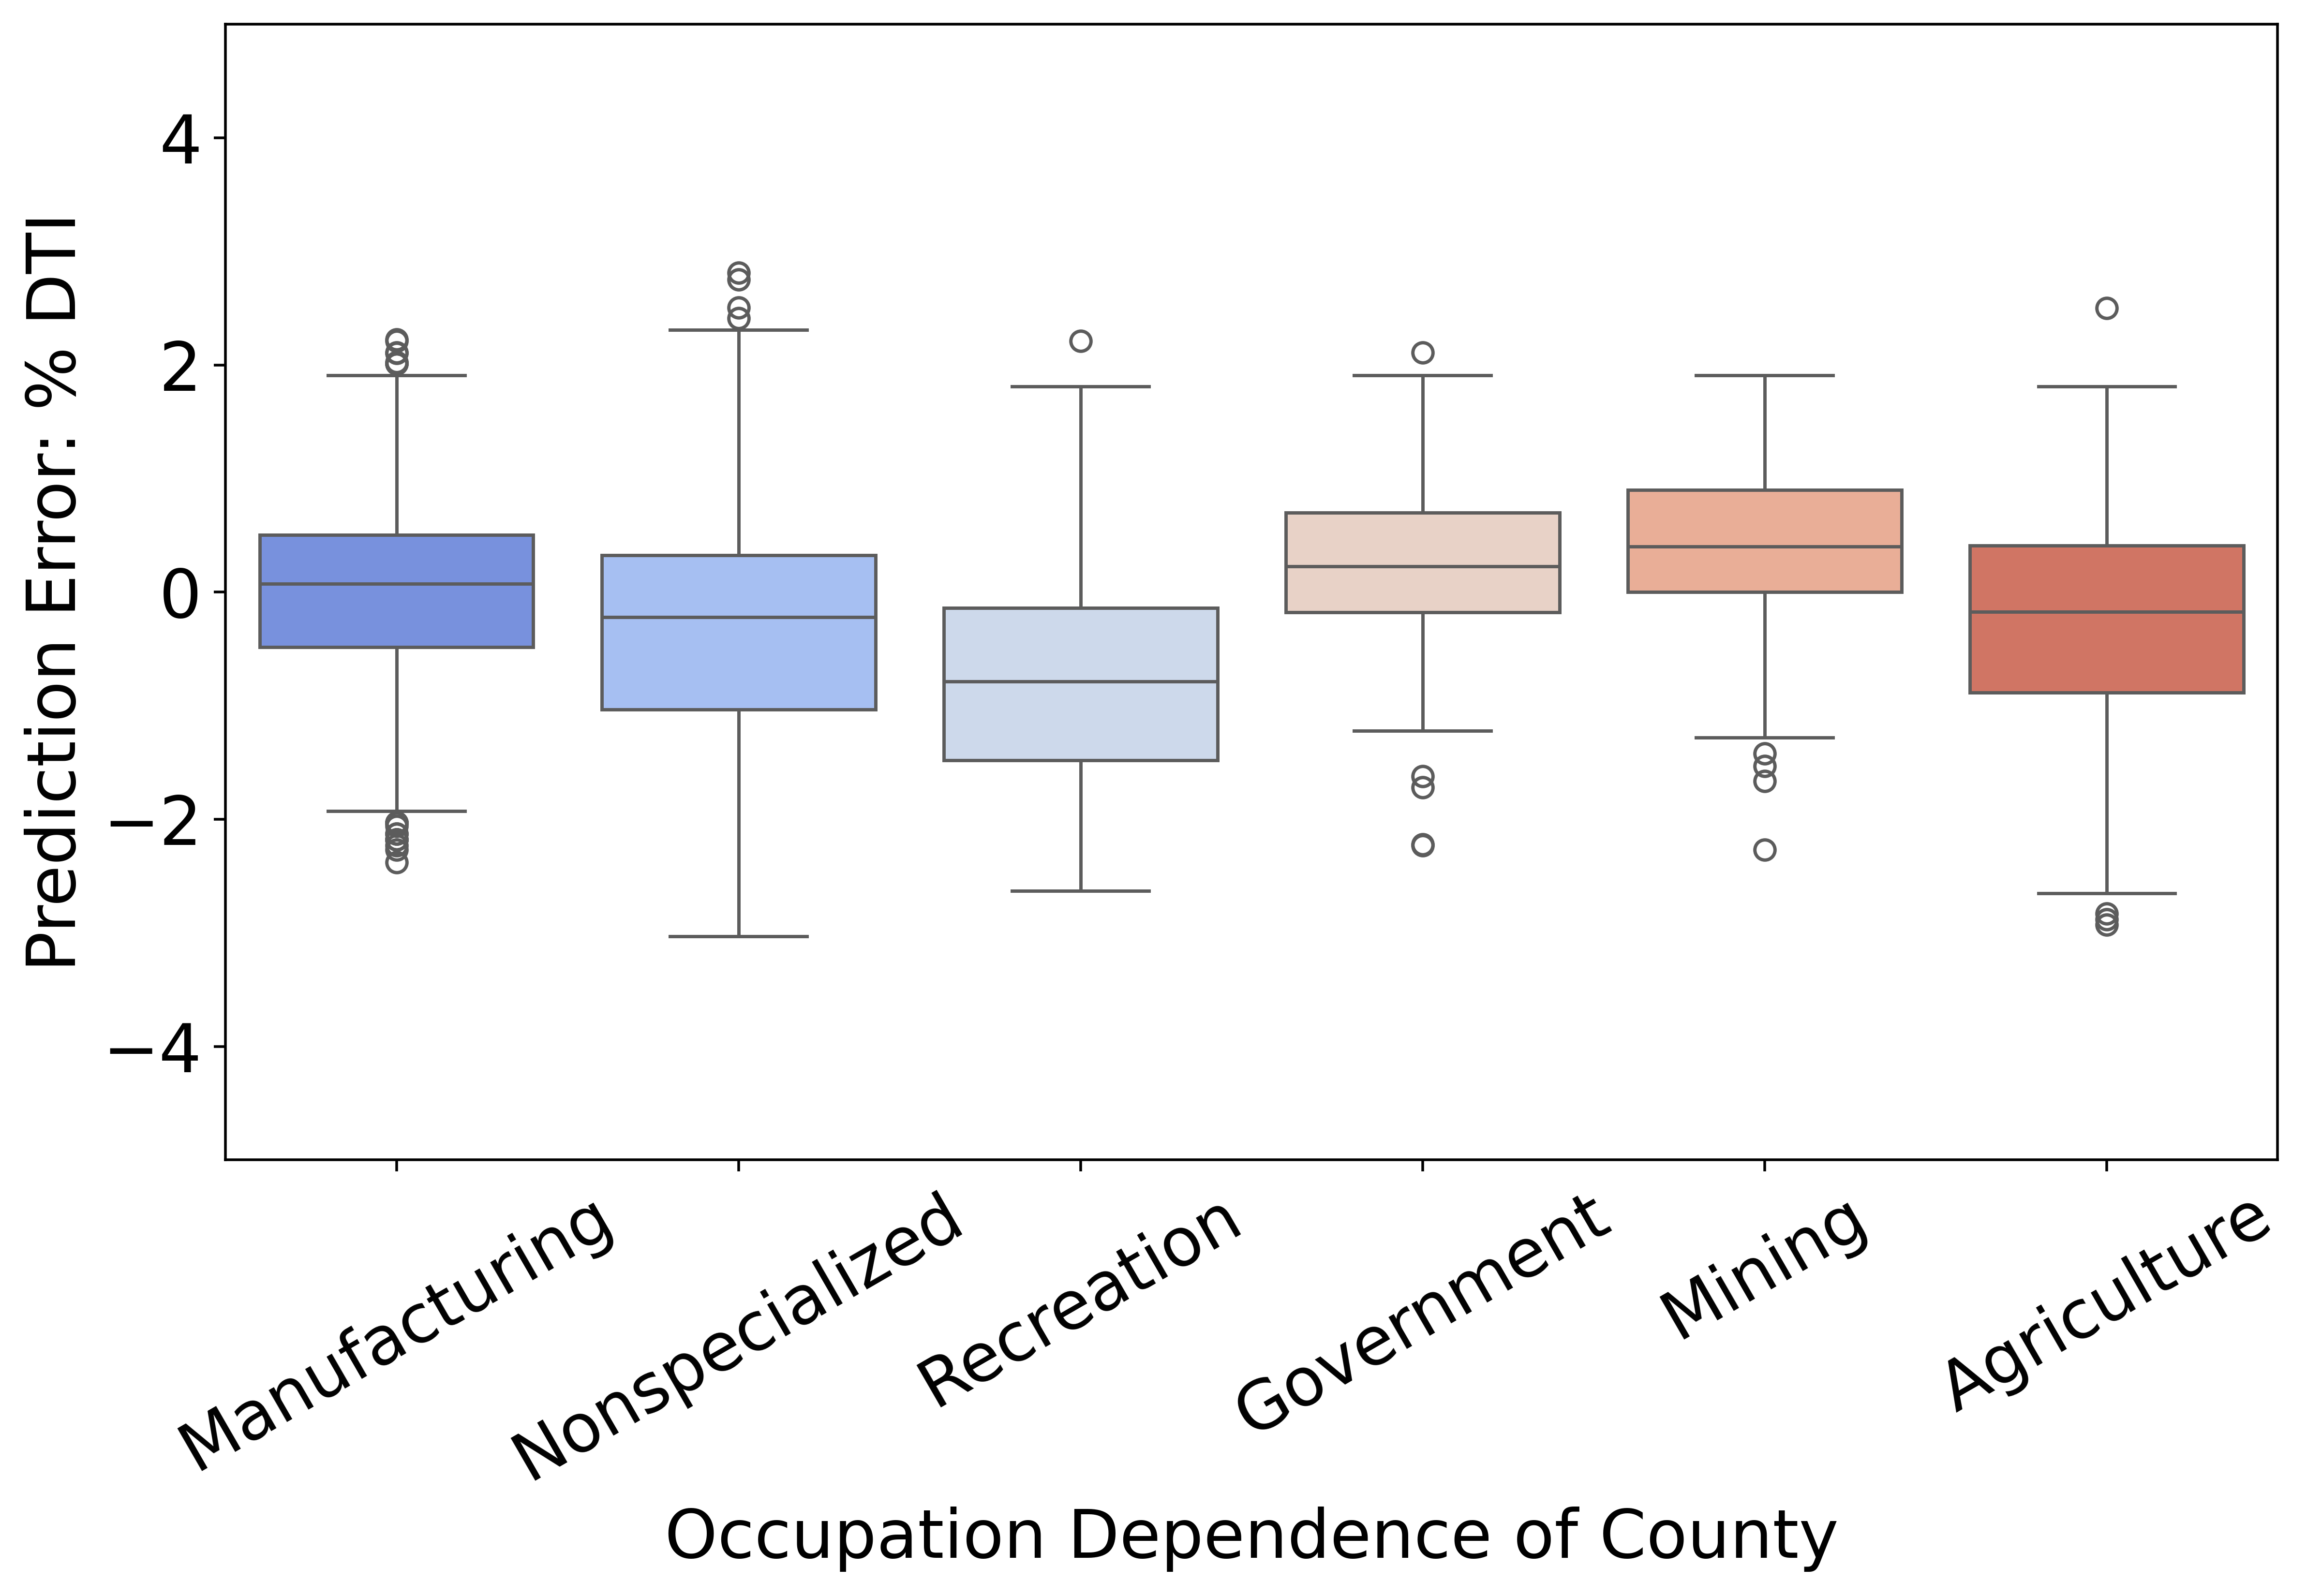

In [118]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged["OccupationType"] = merged["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % DTI')

plt.ylim(-5, 5)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [119]:
group_stats = merged.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture   -0.257989
1      Government    0.208172
2   Manufacturing   -0.013038
3          Mining    0.346798
4  Nonspecialized   -0.357643
5      Recreation   -0.751189


In [120]:
merged = merged.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0    1570
3     706
1     353
5     265
4     145
2      89
Name: count, dtype: int64


In [121]:
from scipy.stats import f_oneway

occ_groups = [
    merged.loc[merged["Value"] == cat, "Difference"]
    for cat in sorted(merged["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 42.248, p-value: 0.0000


In [122]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged["Difference"],
    groups=merged["Value"],
    alpha=0.05
)
print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.0997 0.4654 -0.0582  0.2575  False
     0      2   0.7044    0.0  0.4125  0.9964   True
     0      3   0.3446    0.0  0.2232   0.466   True
     0      4   0.5658    0.0  0.3333  0.7983   True
     0      5  -0.3935    0.0 -0.5715 -0.2156   True
     1      2   0.6048    0.0   0.287  0.9225   True
     1      3    0.245 0.0009  0.0703  0.4196   True
     1      4   0.4662    0.0  0.2019  0.7304   True
     1      5  -0.4932    0.0  -0.711 -0.2754   True
     2      3  -0.3598 0.0088 -0.6612 -0.0585   True
     2      4  -0.1386 0.8832 -0.4994  0.2221  False
     2      5   -1.098    0.0 -1.4262 -0.7698   True
     3      4   0.2212 0.1018  -0.023  0.4655  False
     3      5  -0.7382    0.0 -0.9312 -0.5451   True
     4      5  -0.9594    0.0 -1.2361 -0.6826   True
----------------------------------------------

#

#DTI OpenAI 120b

In [123]:
model2 = pd.read_csv('/content/dti_merged_data_openai_gpt-oss-120b.csv')

In [124]:
merged2 = model2.merge(filt_df, on="county_fips", how="left")

merged2 = merged2.dropna(subset=["county"])

merged2.head()

,county_fips,county,estimate,low,high,mean_col,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1015,"Calhoun County, AL",1.15,1.37,1.58,1.475,-0.325,AL,Calhoun County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1001,"Autauga County, AL",1.15,2.61,3.43,3.020,-1.870,AL,Autauga County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1009,"Blount County, AL",1.12,3.43,3.43,3.430,-2.310,AL,Blount County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1011,"Bullock County, AL",1.30,0.78,1.01,0.895,0.405,AL,Bullock County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1007,"Bibb County, AL",0.75,1.82,2.15,1.985,-1.235,AL,Bibb County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_723/2723745835.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged2, palette="coolwarm")


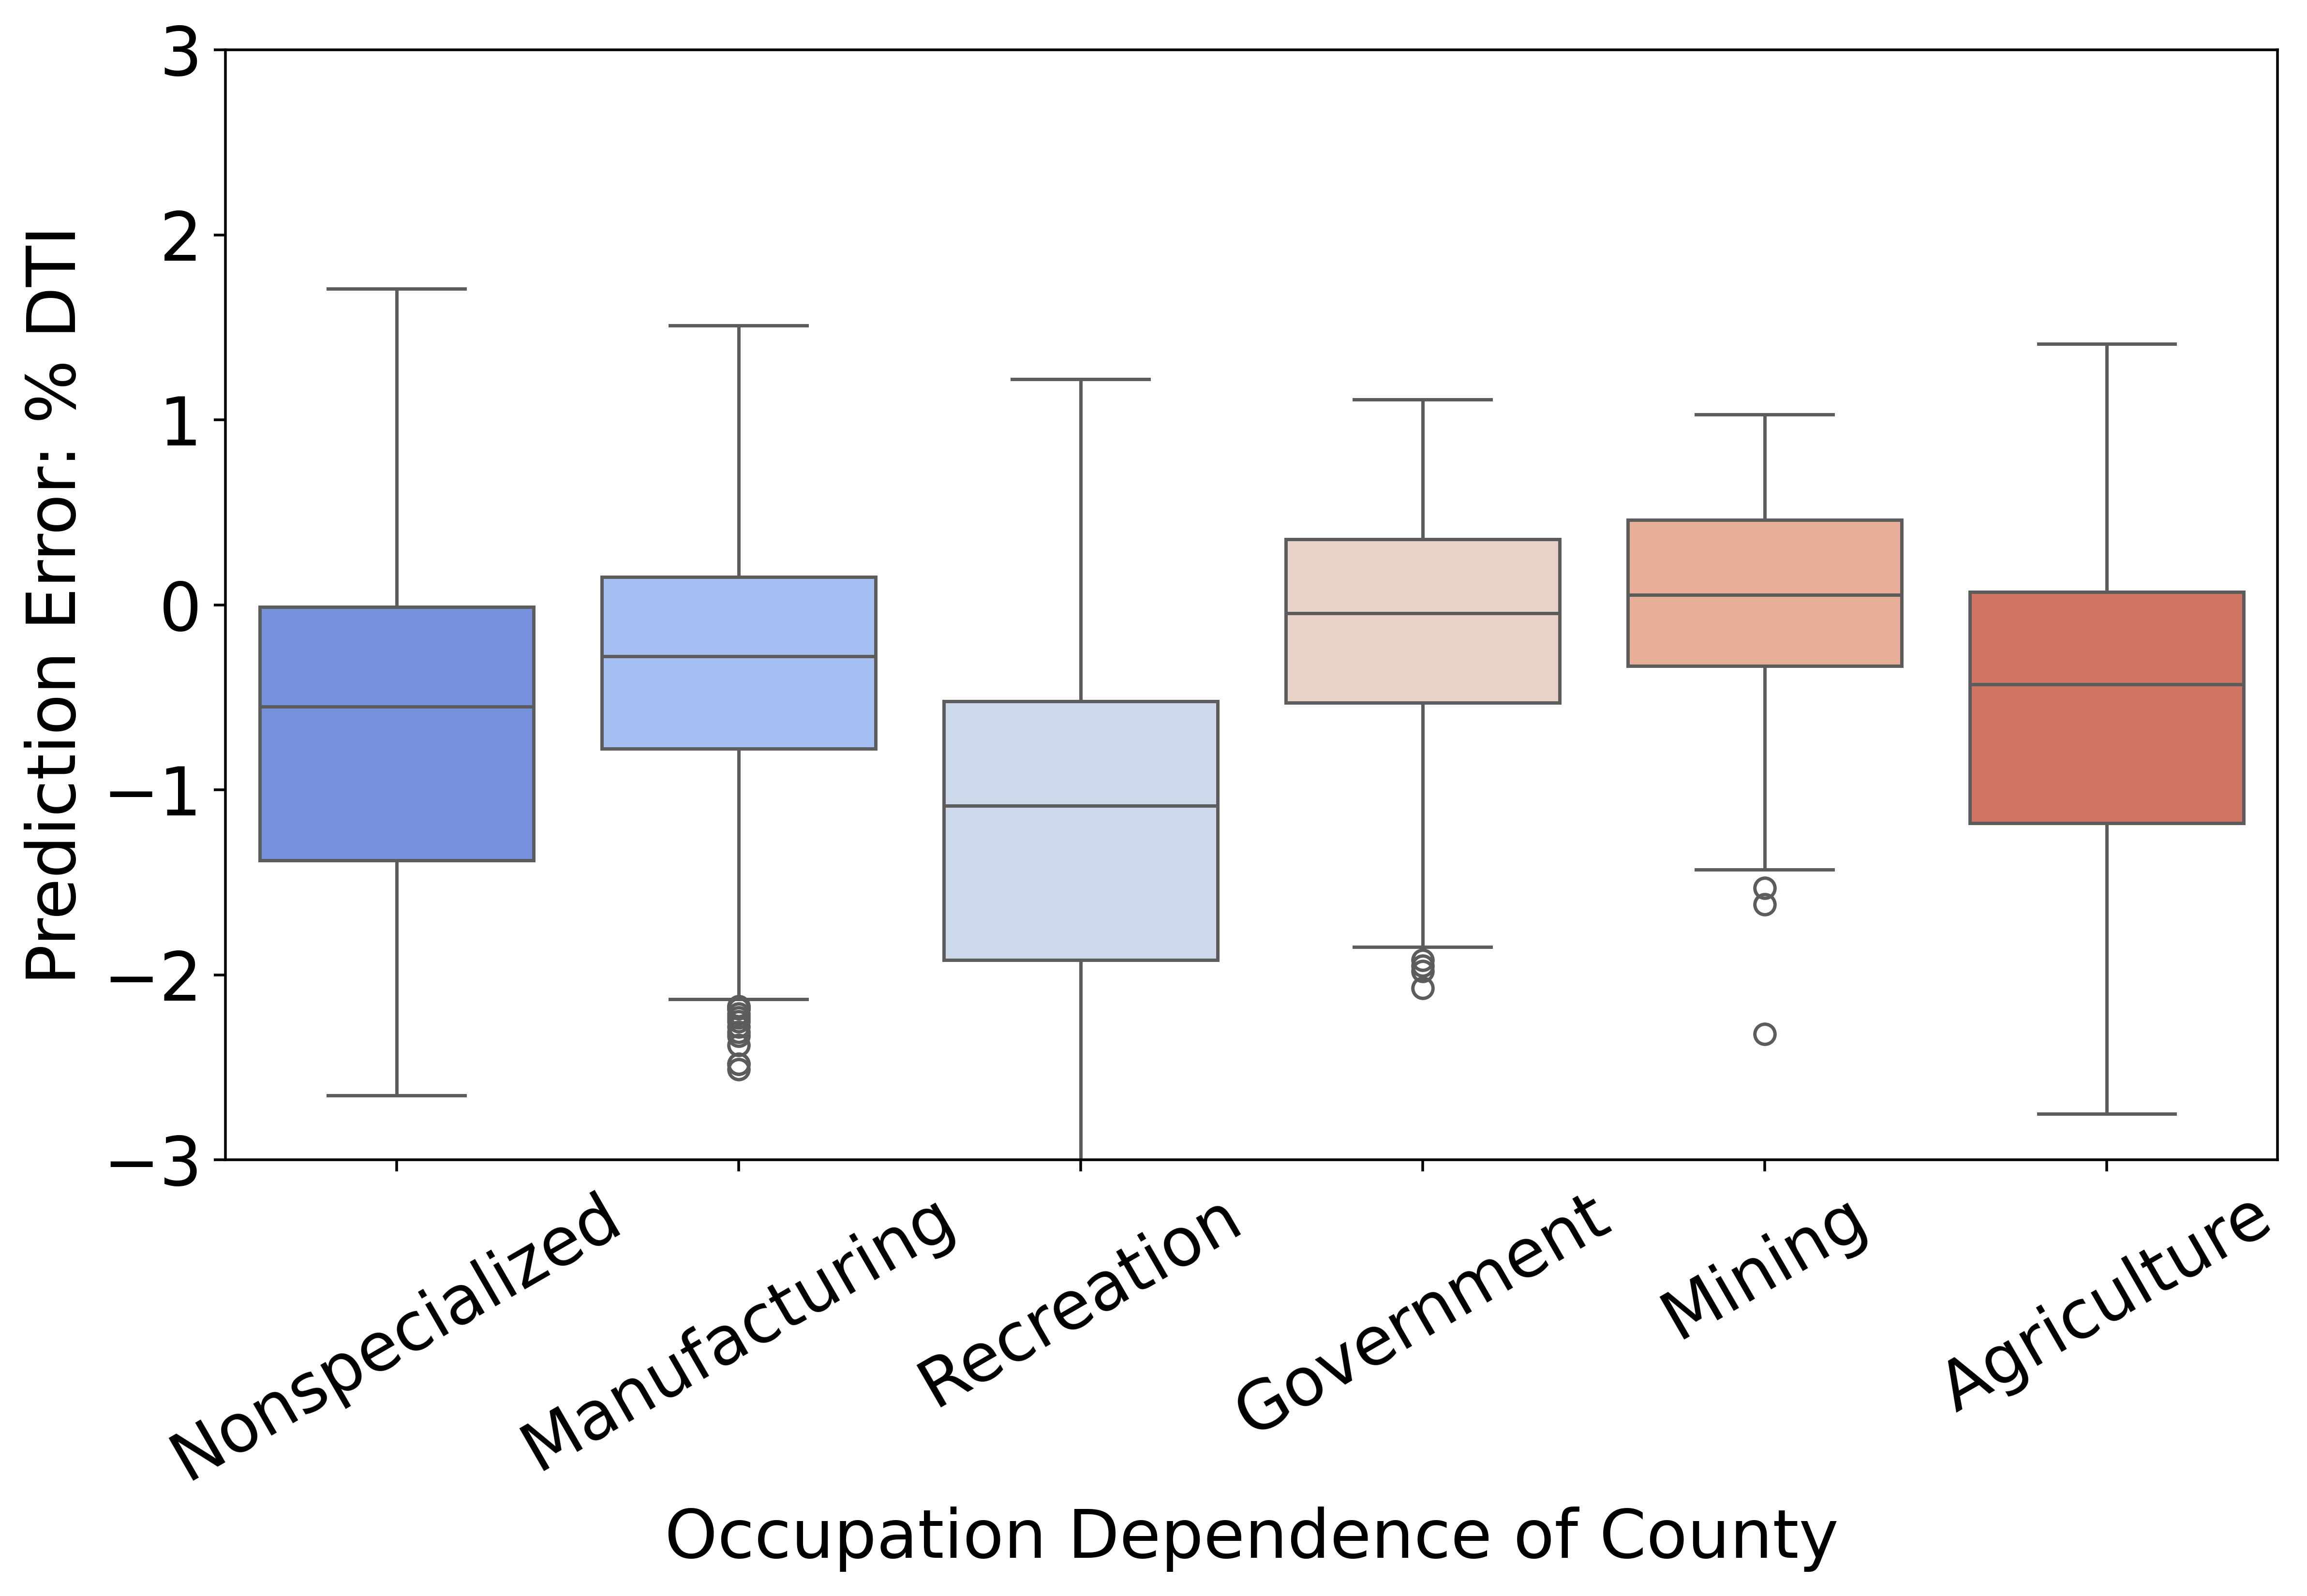

In [125]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged2["OccupationType"] = merged2["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged2, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % DTI')

plt.ylim(-3, 3)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [126]:
group_stats = merged2.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture   -0.595779
1      Government   -0.164862
2   Manufacturing   -0.356197
3          Mining    0.001404
4  Nonspecialized   -0.705656
5      Recreation   -1.128698


In [127]:
merged2 = merged2.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0    1570
3     706
1     353
5     265
4     145
2      89
Name: count, dtype: int64


In [128]:
from scipy.stats import f_oneway

occ_groups = [
    merged2.loc[merged2["Value"] == cat, "Difference"]
    for cat in sorted(merged2["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 51.187, p-value: 0.0000


In [129]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged2["Difference"],
    groups=merged2["Value"],
    alpha=0.05
)
print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.1099 0.2633  -0.036  0.2558  False
     0      2   0.7071    0.0  0.4372   0.977   True
     0      3   0.3495    0.0  0.2372  0.4617   True
     0      4   0.5408    0.0  0.3258  0.7558   True
     0      5   -0.423    0.0 -0.5875 -0.2585   True
     1      2   0.5972    0.0  0.3034   0.891   True
     1      3   0.2396 0.0003  0.0781  0.4011   True
     1      4   0.4309    0.0  0.1866  0.6752   True
     1      5  -0.5329    0.0 -0.7343 -0.3316   True
     2      3  -0.3576 0.0035 -0.6362  -0.079   True
     2      4  -0.1663  0.714 -0.4998  0.1673  False
     2      5  -1.1301    0.0 -1.4336 -0.8266   True
     3      4   0.1913  0.151 -0.0345  0.4172  False
     3      5  -0.7725    0.0  -0.951  -0.594   True
     4      5  -0.9638    0.0 -1.2197  -0.708   True
----------------------------------------------

#DTI llama 3.1-8b

In [130]:
model4 = pd.read_csv('/content/dti_merged_data_llama-3.1-8b-instruct.csv')
model4.head()

,county_fips,county,estimate,low,high,mean_col,Difference
0,1065,"Hale County, AL",1.340000,2.15,2.61,2.38,-1.040000
1,1061,"Geneva County, AL",1.320000,3.43,3.43,3.43,-2.110000
2,1099,"Monroe County, AL",1.350000,1.01,1.19,1.10,0.250000
3,1097,"Mobile County, AL",1.380000,1.01,1.19,1.10,0.280000
4,1019,"Cherokee County, AL",2.571429,2.61,3.43,3.02,-0.448571


In [131]:
merged4 = model4.merge(filt_df, on="county_fips", how="left")

merged4 = merged4.dropna(subset=["county"])

merged4.head()

,county_fips,county,estimate,low,high,mean_col,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1065,"Hale County, AL",1.340000,2.15,2.61,2.38,-1.040000,AL,Hale County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1061,"Geneva County, AL",1.320000,3.43,3.43,3.43,-2.110000,AL,Geneva County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1099,"Monroe County, AL",1.350000,1.01,1.19,1.10,0.250000,AL,Monroe County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1097,"Mobile County, AL",1.380000,1.01,1.19,1.10,0.280000,AL,Mobile County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1019,"Cherokee County, AL",2.571429,2.61,3.43,3.02,-0.448571,AL,Cherokee County,0,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_723/4178676477.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged4, palette="coolwarm")


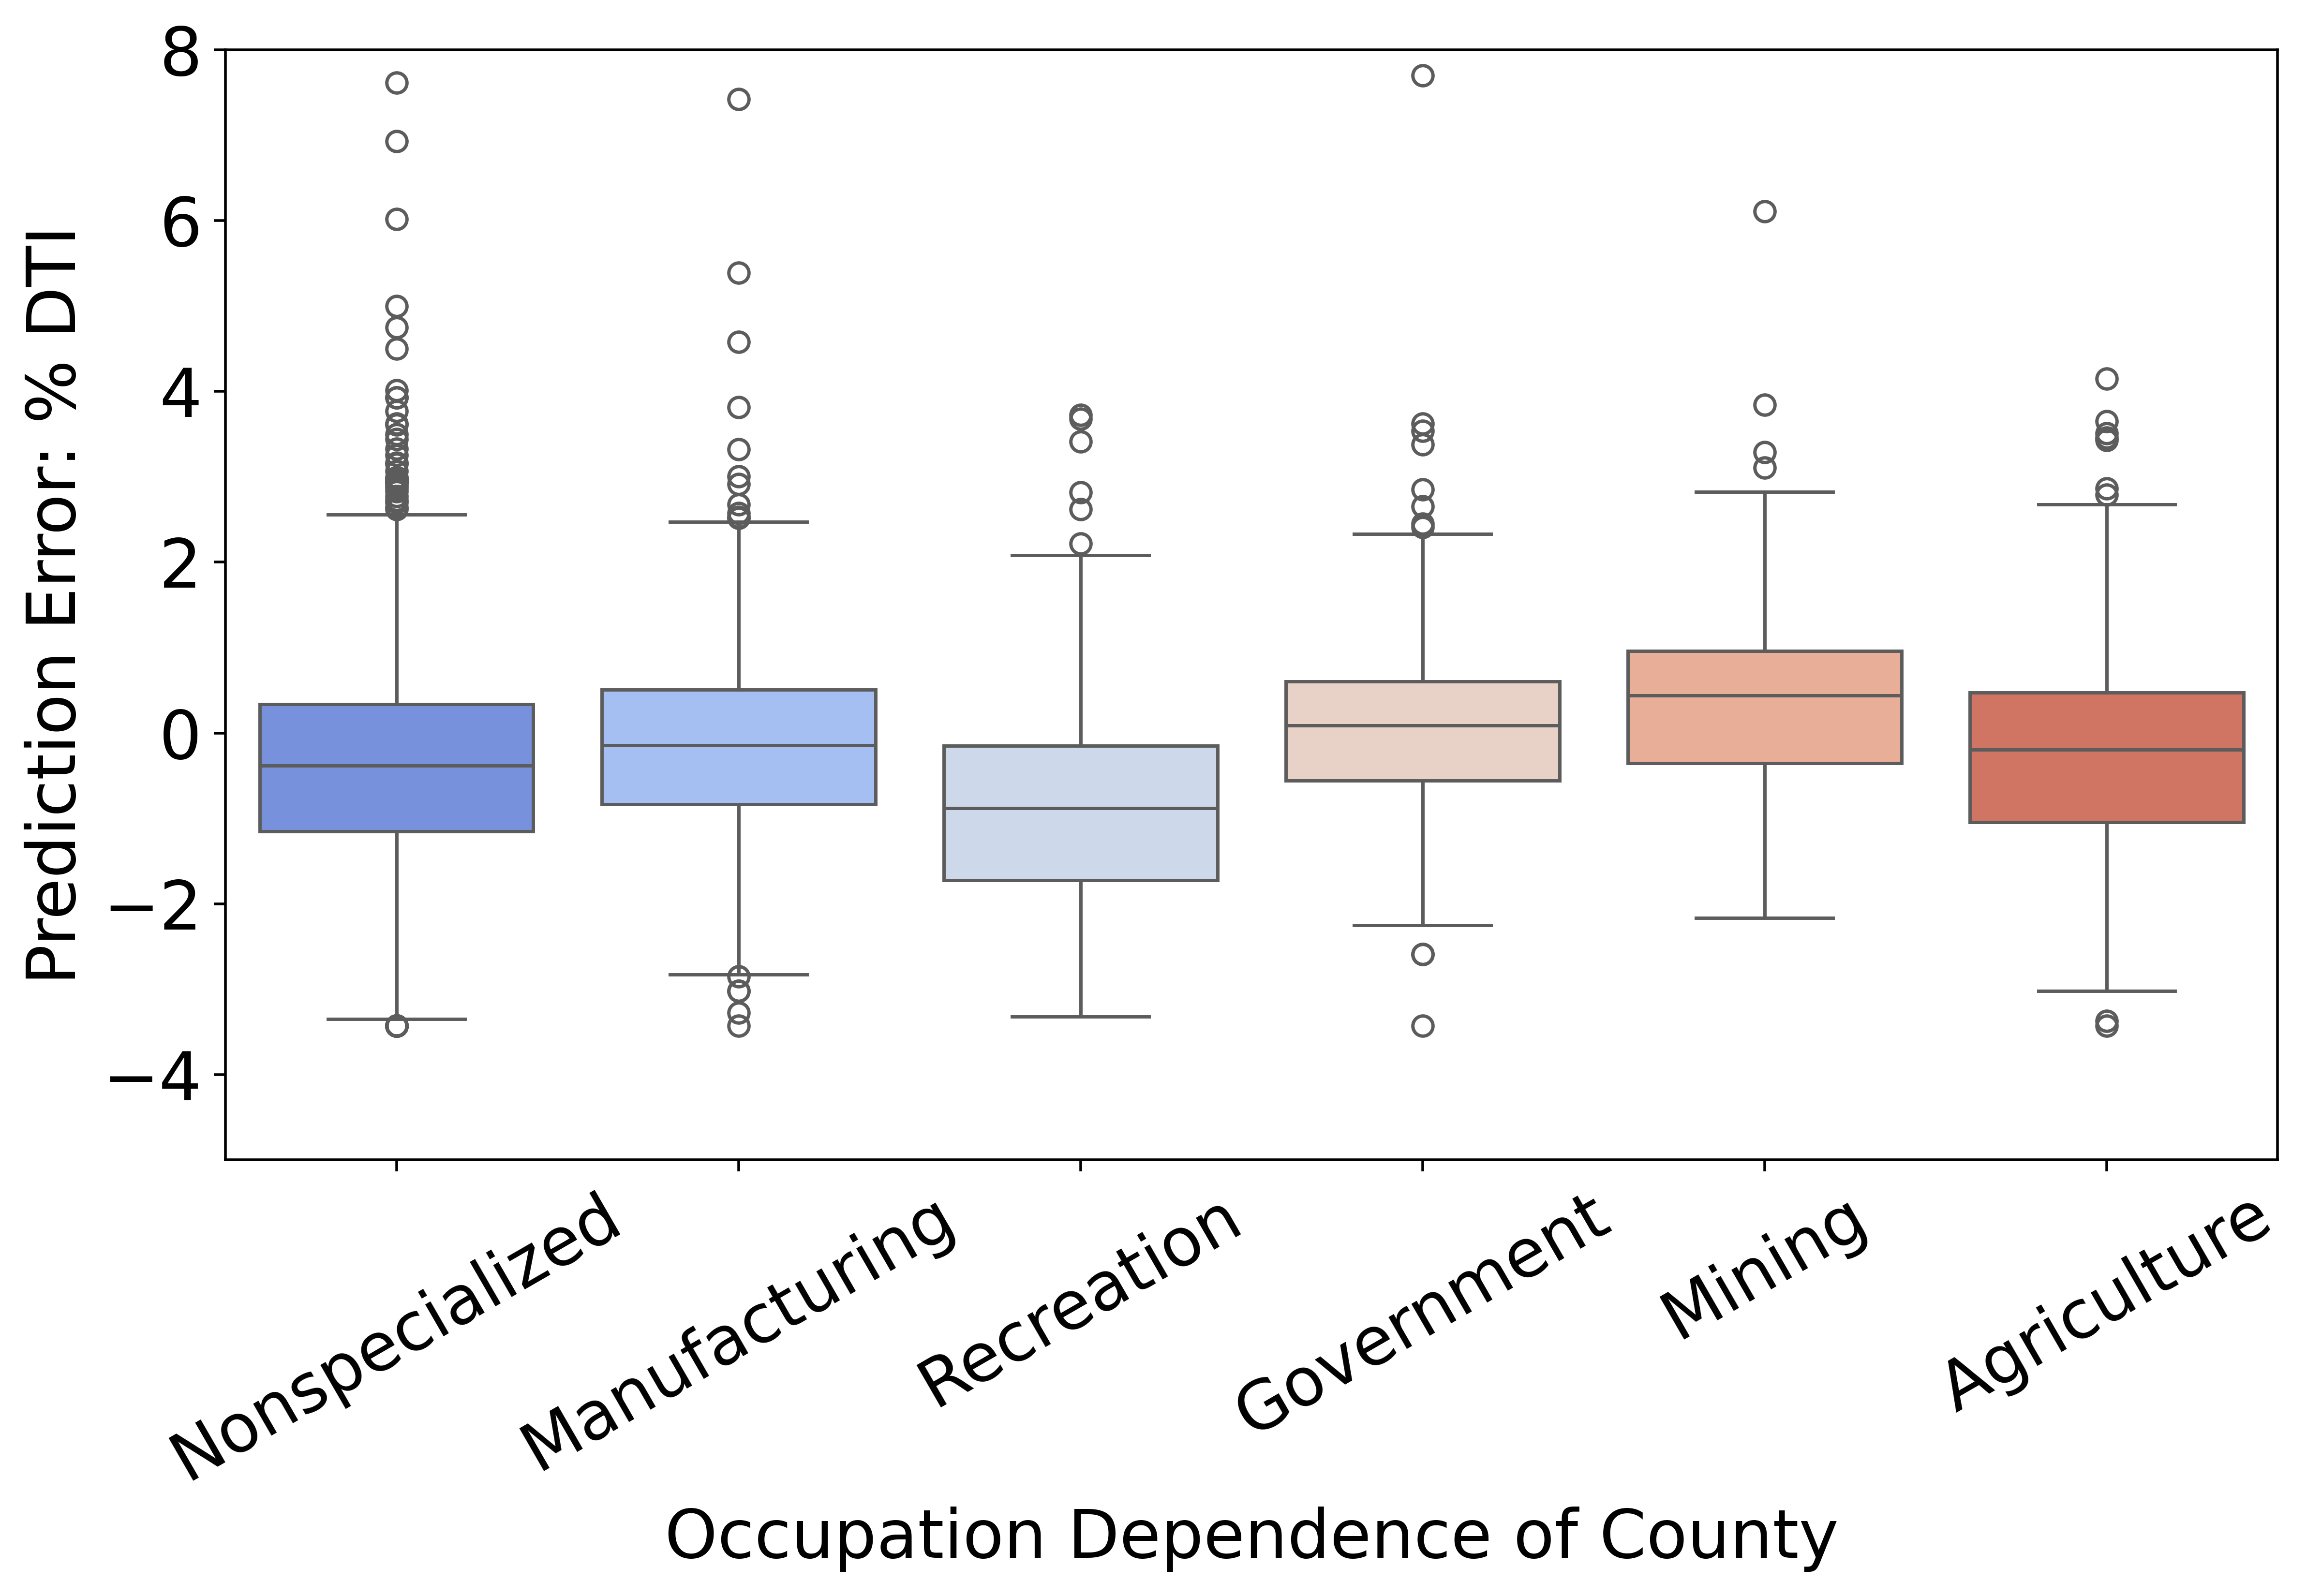

In [132]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged4["OccupationType"] = merged4["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged4, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % DTI')

plt.ylim(-5, 8)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [133]:
group_stats = merged4.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture   -0.234055
1      Government    0.140597
2   Manufacturing   -0.143257
3          Mining    0.569967
4  Nonspecialized   -0.386424
5      Recreation   -0.822225


In [134]:
merged4 = merged4.dropna(subset=["Value", "Difference"])
print(merged4["Value"].value_counts(dropna=False))


Value
0    1562
3     705
1     352
5     264
4     144
2      89
Name: count, dtype: int64


In [135]:
from scipy.stats import f_oneway

occ_groups = [
    merged4.loc[merged4["Value"] == cat, "Difference"]
    for cat in sorted(merged4["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 24.481, p-value: 0.0000


In [136]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged4["Difference"],
    groups=merged4["Value"],
    alpha=0.05
)
print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   0.1524 0.3246 -0.0615  0.3663  False
     0      2   0.9564    0.0  0.5613  1.3514   True
     0      3   0.2432 0.0004  0.0787  0.4076   True
     0      4    0.527    0.0  0.2113  0.8427   True
     0      5  -0.4358    0.0  -0.677 -0.1946   True
     1      2    0.804    0.0  0.3739  1.2341   True
     1      3   0.0908 0.8838 -0.1458  0.3274  False
     1      4   0.3747 0.0346  0.0161  0.7332   True
     1      5  -0.5882    0.0 -0.8833  -0.293   True
     2      3  -0.7132    0.0  -1.121 -0.3054   True
     2      4  -0.4294 0.1229 -0.9182  0.0594  False
     2      5  -1.3922    0.0 -1.8365 -0.9479   True
     3      4   0.2839 0.1424 -0.0477  0.6154  False
     3      5   -0.679    0.0 -0.9405 -0.4174   True
     4      5  -0.9628    0.0 -1.3384 -0.5873   True
----------------------------------------------

#DTI llama 3.3 70b

In [137]:
model3 = pd.read_csv('/content/dti_merged_data_llama-3.3-70b-instruct.csv')

In [138]:
merged3 = model3.merge(filt_df, on="county_fips", how="left")

merged3 = merged3.dropna(subset=["county"])

merged3.head()

,county_fips,county,estimate,low,high,mean_col,Difference,State,County_Name,Metro2023,Attribute,Value,PublicationDate,Source
0,1003,"Baldwin County, AL",1.23,2.61,3.43,3.020,-1.790,AL,Baldwin County,1,Industry_Dependence_2025,5,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
1,1001,"Autauga County, AL",1.23,2.61,3.43,3.020,-1.790,AL,Autauga County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
2,1007,"Bibb County, AL",1.23,1.82,2.15,1.985,-0.755,AL,Bibb County,1,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
3,1005,"Barbour County, AL",1.23,1.01,1.19,1.100,0.130,AL,Barbour County,0,Industry_Dependence_2025,3,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."
4,1039,"Covington County, AL",1.23,1.58,1.82,1.700,-0.470,AL,Covington County,0,Industry_Dependence_2025,0,Data as of April 2025,"Source: USDA, Economic Research Service, Count..."


/tmp/ipykernel_723/2936990866.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="OccupationType", y="Difference", data=merged3, palette="coolwarm")


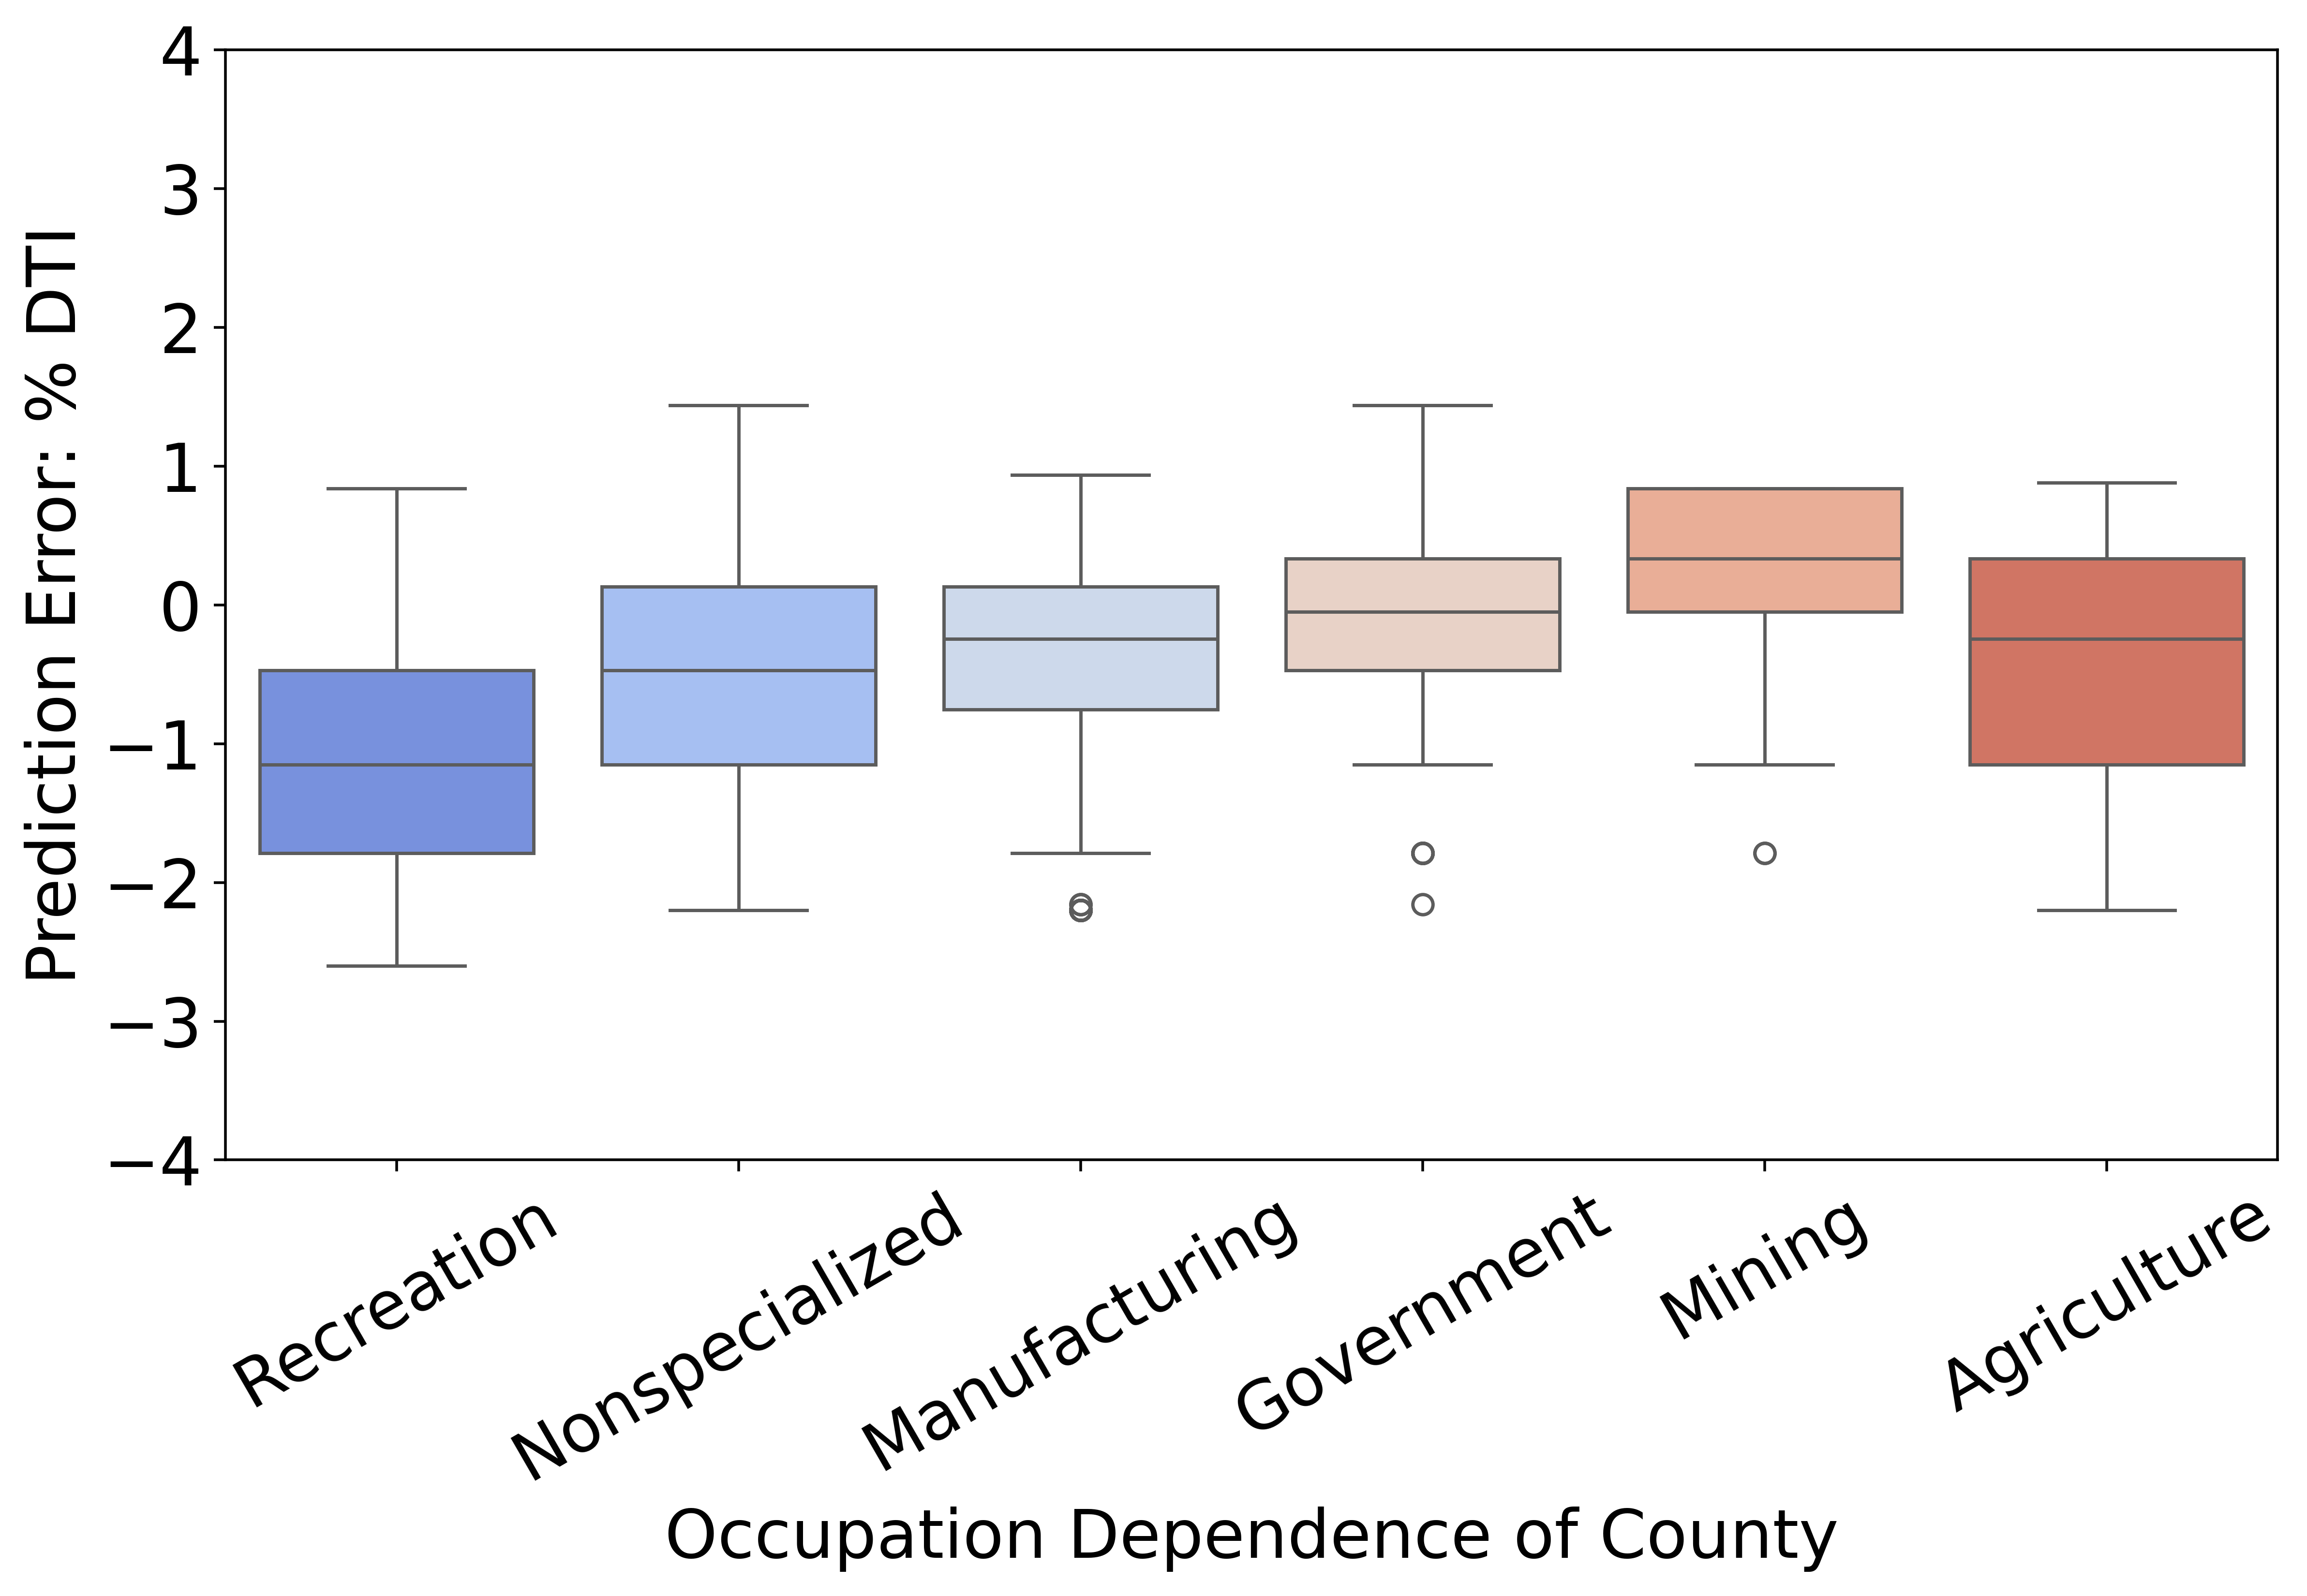

In [139]:
import seaborn as sns
import matplotlib.pyplot as plt

occ_labels = {
    0: "Nonspecialized",
    1: "Agriculture",
    2: "Mining",
    3: "Manufacturing",
    4: "Government",
    5: "Recreation",
}
merged3["OccupationType"] = merged3["Value"].map(occ_labels)

plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 7), dpi=500)

sns.boxplot(x="OccupationType", y="Difference", data=merged3, palette="coolwarm")
plt.xlabel('Occupation Dependence of County')
plt.ylabel('Prediction Error: % DTI')

plt.ylim(-4, 4)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


In [140]:
group_stats = merged3.groupby("OccupationType")["Difference"].mean().reset_index()
group_stats = group_stats.sort_values("OccupationType")
print(group_stats)


   OccupationType  Difference
0     Agriculture   -0.380680
1      Government   -0.082379
2   Manufacturing   -0.300418
3          Mining    0.177022
4  Nonspecialized   -0.636662
5      Recreation   -1.024623


In [141]:
merged3 = merged3.dropna(subset=["Value", "Difference"])
print(merged["Value"].value_counts(dropna=False))


Value
0    1570
3     706
1     353
5     265
4     145
2      89
Name: count, dtype: int64


In [142]:
from scipy.stats import f_oneway

occ_groups = [
    merged3.loc[merged3["Value"] == cat, "Difference"]
    for cat in sorted(merged3["Value"].unique())
]

f_stat, p_val = f_oneway(*occ_groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val:.4f}")


F-statistic: 57.104, p-value: 0.0000


In [143]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=merged3["Difference"],
    groups=merged3["Value"],
    alpha=0.05
)
print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1    0.256    0.0  0.1152  0.3968   True
     0      2   0.8137    0.0  0.5532  1.0742   True
     0      3   0.3362    0.0  0.2279  0.4446   True
     0      4   0.5543    0.0  0.3468  0.7618   True
     0      5   -0.388    0.0 -0.5467 -0.2292   True
     1      2   0.5577    0.0  0.2741  0.8413   True
     1      3   0.0803 0.6844 -0.0756  0.2361  False
     1      4   0.2983 0.0043  0.0625  0.5341   True
     1      5  -0.6439    0.0 -0.8383 -0.4496   True
     2      3  -0.4774    0.0 -0.7464 -0.2085   True
     2      4  -0.2594 0.1952 -0.5813  0.0625  False
     2      5  -1.2016    0.0 -1.4945 -0.9088   True
     3      4    0.218 0.0499  0.0001   0.436   True
     3      5  -0.7242    0.0 -0.8964  -0.552   True
     4      5  -0.9422    0.0 -1.1892 -0.6953   True
----------------------------------------------